# Late Fusion Model — Visual + Audio Combination

Combines per-clip predictions from the human-trained visual model and the audio model into a single AV prediction via linear regression, calibrated against per-clip mean human estimates from the AV condition.

## Architecture
Late fusion at the prediction level:
```
visual_pred (from visual_predict_travel)  ─┐
                                            ├─→ pred_av = w_v·visual + w_a·audio + b
audio_pred  (from audio_model)             ─┘
```

## Inputs
- `results/visual/travel/travel_clip_predictions_human.csv` — visual predictions per clip (36 rows)
- `results/audio/summary.csv` — audio predictions per clip (36 rows)
- `data/labels/video_perceived.csv` — V-condition per-clip mean human estimates
- `data/labels/audio_perceived.csv` — A-condition per-clip mean human estimates
- `data/labels/av_perceived.csv` — AV-condition per-clip mean human estimates (regression target)

## Outputs
- `results/fusion/fusion_predictions.csv` — per-clip predictions with all three modalities
- `results/fusion/fusion_metrics.json` — performance metrics
- `results/fusion/fusion_*.png` — comparison plots

In [1]:
# ============================================================================
# SECTION 1: Imports and Paths
# ============================================================================

import json
import pickle
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
from scipy.stats import pearsonr

PROJECT_ROOT = Path.cwd().parent
VISUAL_PRED_PATH = PROJECT_ROOT / "results" / "visual" / "travel" / "travel_clip_predictions_human.csv"
AUDIO_PRED_PATH  = PROJECT_ROOT / "results" / "audio" / "summary.csv"

LABELS_DIR = PROJECT_ROOT / "data" / "labels"
V_LABELS_PATH  = LABELS_DIR / "video_perceived.csv"
A_LABELS_PATH  = LABELS_DIR / "audio_perceived.csv"
AV_LABELS_PATH = LABELS_DIR / "av_perceived.csv"

OUT_DIR = PROJECT_ROOT / "results" / "fusion"
OUT_DIR.mkdir(parents=True, exist_ok=True)

for p in [VISUAL_PRED_PATH, AUDIO_PRED_PATH, V_LABELS_PATH, A_LABELS_PATH, AV_LABELS_PATH]:
    assert p.exists(), f"Missing required input: {p}"

print("All input files present.")

All input files present.


In [2]:
# ============================================================================
# SECTION 2: Load and Align Per-Clip Predictions and Labels
# ============================================================================

def normalise_clip_id(s):
    """Clip IDs come in different formats across files. Normalise to plain int string."""
    s = str(s).strip().replace("_processed", "")
    # Handle e.g. "clip_05" → "5", "05" → "5"
    digits = "".join(c for c in s if c.isdigit())
    return digits.lstrip("0") or "0"

# Load visual predictions (already trained on professor's humans)
vis = pd.read_csv(VISUAL_PRED_PATH)
vis = vis[["clip_id", "duration_s", "pred_perceived_s"]].rename(
    columns={"pred_perceived_s": "visual_pred"}
)
vis["clip_id"] = vis["clip_id"].apply(normalise_clip_id)

# Load audio predictions
aud = pd.read_csv(AUDIO_PRED_PATH)
audio_pred_col = "pred_perceived_s" if "pred_perceived_s" in aud.columns else "ticks"
aud = aud[["clip_id", audio_pred_col]].rename(columns={audio_pred_col: "audio_pred"})
aud["clip_id"] = aud["clip_id"].apply(normalise_clip_id)

# Load human labels for all three conditions
def load_labels(path, suffix):
    df = pd.read_csv(path)[["clip_id", "perceived_s"]].rename(
        columns={"perceived_s": f"human_{suffix}"}
    )
    df["clip_id"] = df["clip_id"].apply(normalise_clip_id)
    return df

v_labels  = load_labels(V_LABELS_PATH,  "v")
a_labels  = load_labels(A_LABELS_PATH,  "a")
av_labels = load_labels(AV_LABELS_PATH, "av")

# Merge everything on clip_id
df = (vis
      .merge(aud,       on="clip_id", how="inner")
      .merge(v_labels,  on="clip_id", how="inner")
      .merge(a_labels,  on="clip_id", how="inner")
      .merge(av_labels, on="clip_id", how="inner"))

df = df.sort_values("clip_id", key=lambda s: s.astype(int)).reset_index(drop=True)

print(f"Aligned dataset: {len(df)} clips")
print(df.head())
print()
print("Summary:")
print(df[["duration_s", "visual_pred", "audio_pred",
          "human_v", "human_a", "human_av"]].describe().round(2))

Aligned dataset: 36 clips
  clip_id  duration_s  visual_pred  audio_pred  human_v  human_a  human_av
0       1   24.600000    22.829178          22   17.750   25.333    15.875
1       2   23.966667    27.811617          21   16.500   18.250    17.667
2       3   24.100000    17.882811          22   16.250   19.500    21.000
3       4   26.566668    29.239087          25   19.167   22.333    23.429
4       5   23.833334    12.529307          22   18.200   17.833    18.667

Summary:
       duration_s  visual_pred  audio_pred  human_v  human_a  human_av
count       36.00        36.00       36.00    36.00    36.00     36.00
mean        23.44        16.88       20.75    17.53    19.63     18.38
std          4.28         7.75        3.78     3.72     4.02      3.50
min         16.10         5.21       15.00    10.00    12.00      9.33
25%         20.31         9.38       18.00    15.20    16.38     16.53
50%         23.82        16.31       20.00    17.54    19.32     18.12
75%         25.07

In [3]:
# ============================================================================
# SECTION 3: Single-Modality Baselines
# Evaluate visual alone (against V condition) and audio alone (against A condition)
# ============================================================================

def evaluate(pred, target, label):
    r = pearsonr(pred, target)[0]
    mae = np.mean(np.abs(pred - target))
    rmse = np.sqrt(np.mean((pred - target) ** 2))
    bias = np.mean(pred - target)
    return {
        "label": label,
        "r":    float(r),
        "mae":  float(mae),
        "rmse": float(rmse),
        "bias": float(bias),
    }

single_baselines = []
single_baselines.append(evaluate(
    df["visual_pred"].values, df["human_v"].values,
    "Visual-only vs V-condition humans"
))
single_baselines.append(evaluate(
    df["audio_pred"].values, df["human_a"].values,
    "Audio-only vs A-condition humans"
))

print("Single-Modality Baselines")
print("=" * 70)
for m in single_baselines:
    print(f"{m['label']:50s}")
    print(f"  r={m['r']:.3f}  MAE={m['mae']:.2f}s  RMSE={m['rmse']:.2f}s  bias={m['bias']:+.2f}s")

Single-Modality Baselines
Visual-only vs V-condition humans                 
  r=0.497  MAE=5.69s  RMSE=6.66s  bias=-0.65s
Audio-only vs A-condition humans                  
  r=0.690  MAE=2.79s  RMSE=3.23s  bias=+1.12s


In [4]:
# ============================================================================
# SECTION 4: Late Fusion — Linear Regression on AV Human Estimates
# Target: per-clip mean AV-condition human ratings
# Predictors: visual_pred, audio_pred
# Evaluation: Leave-One-Out cross-validation (n=36 means LOO is feasible)
# ============================================================================

X = df[["visual_pred", "audio_pred"]].values
y = df["human_av"].values

# ── Constrained fusion: pred_av = w · visual + (1 - w) · audio ────────────────
# Forces predictions to remain a convex combination of the two modalities,
# avoiding OLS shrinkage toward the mean. No intercept fitted.
print("Late Fusion — Constrained Convex Combination")
print("=" * 70)

# Grid search for best weight
ws = np.linspace(0, 1, 101)
mse_per_w = [
    np.mean((w * df["visual_pred"].values
             + (1 - w) * df["audio_pred"].values
             - y) ** 2)
    for w in ws
]
best_w_v = float(ws[np.argmin(mse_per_w)])
best_w_a = 1.0 - best_w_v

print(f"  Fitted equation:")
print(f"    pred_av = {best_w_v:.3f} · visual_pred + {best_w_a:.3f} · audio_pred")
print()

# Save these so the artifact dict in Section 6 can pick them up
w_v, w_a, b = best_w_v, best_w_a, 0.0

# ── Leave-One-Out cross-validated predictions ────────────────────────────────
loo = LeaveOneOut()
preds_loo = np.zeros_like(y)
for train_idx, test_idx in loo.split(X):
    # Re-tune w on the training fold
    ws_inner = np.linspace(0, 1, 101)
    mse_inner = [
        np.mean((w * X[train_idx, 0] + (1 - w) * X[train_idx, 1] - y[train_idx]) ** 2)
        for w in ws_inner
    ]
    w_train = ws_inner[np.argmin(mse_inner)]
    preds_loo[test_idx] = w_train * X[test_idx, 0] + (1 - w_train) * X[test_idx, 1]

df["fusion_pred"] = preds_loo

fusion_metrics = evaluate(preds_loo, y, "Fusion vs AV-condition humans (LOO-CV)")
print("Cross-validated performance:")
print(f"  r={fusion_metrics['r']:.3f}  "
      f"MAE={fusion_metrics['mae']:.2f}s  "
      f"RMSE={fusion_metrics['rmse']:.2f}s  "
      f"bias={fusion_metrics['bias']:+.2f}s")

# ── Compare against single-modality predictions on AV target (unchanged) ─────
print()
print("Single modalities evaluated against AV-condition humans (reference):")
print("=" * 70)
vis_on_av = evaluate(df["visual_pred"].values, df["human_av"].values,
                     "Visual-only vs AV humans")
aud_on_av = evaluate(df["audio_pred"].values, df["human_av"].values,
                     "Audio-only vs AV humans")
print(f"  Visual-only:  r={vis_on_av['r']:.3f}  MAE={vis_on_av['mae']:.2f}s")
print(f"  Audio-only:   r={aud_on_av['r']:.3f}  MAE={aud_on_av['mae']:.2f}s")
print(f"  Fusion (LOO): r={fusion_metrics['r']:.3f}  MAE={fusion_metrics['mae']:.2f}s")

Late Fusion — Constrained Convex Combination
  Fitted equation:
    pred_av = 0.270 · visual_pred + 0.730 · audio_pred

Cross-validated performance:
  r=0.502  MAE=3.25s  RMSE=4.06s  bias=+1.37s

Single modalities evaluated against AV-condition humans (reference):
  Visual-only:  r=0.450  MAE=6.19s
  Audio-only:   r=0.445  MAE=3.55s
  Fusion (LOO): r=0.502  MAE=3.25s


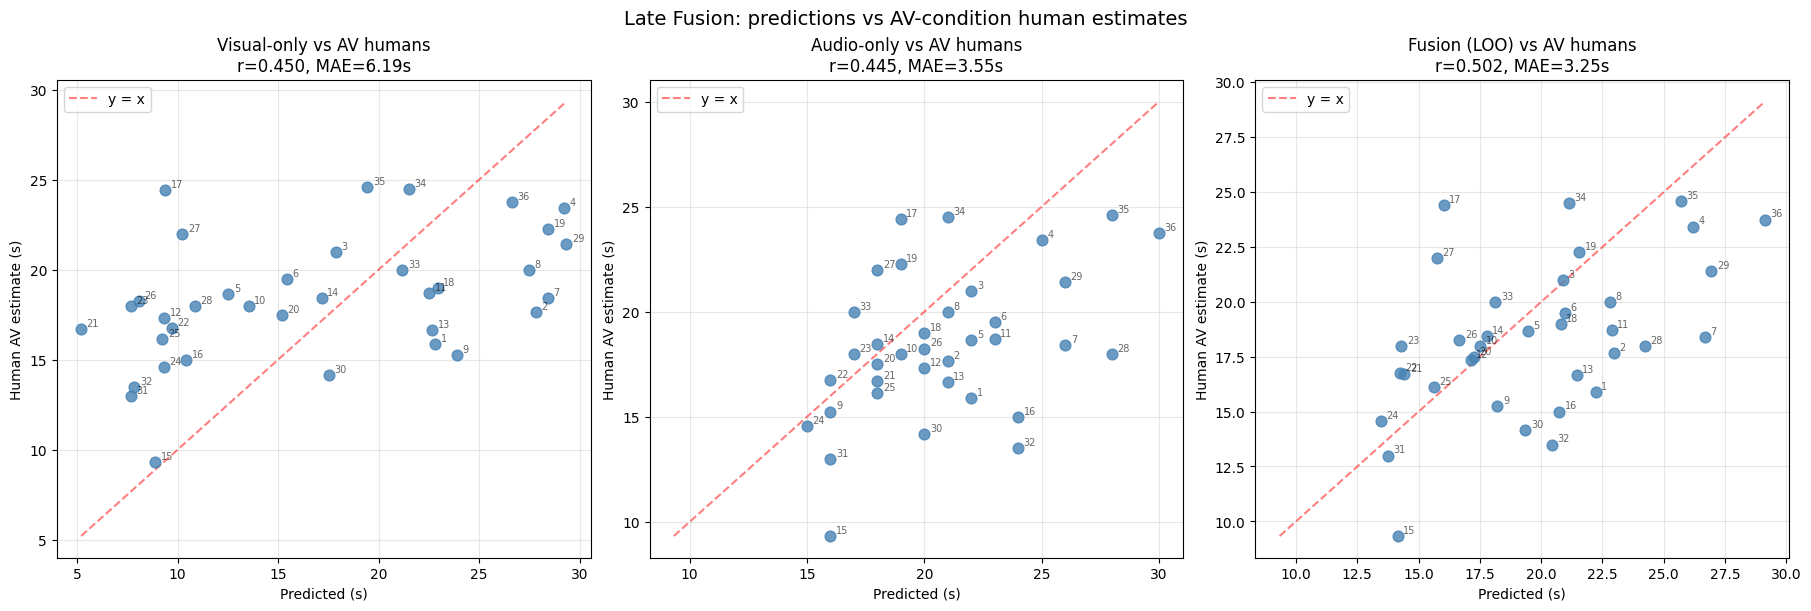

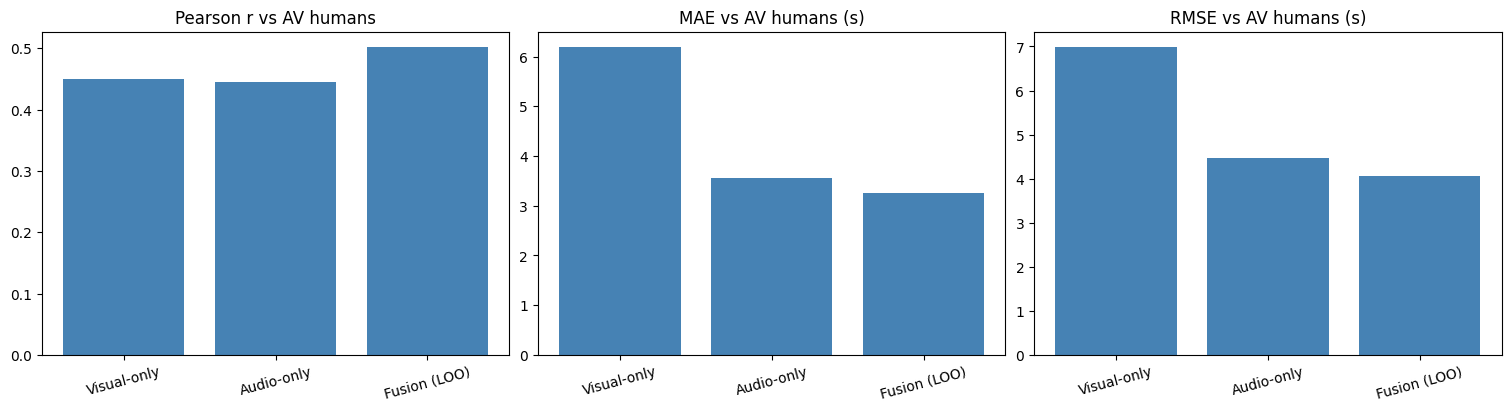

In [5]:
# ============================================================================
# SECTION 5: Visualisations
# ============================================================================

# ── Plot 1: Fusion predictions vs AV humans, scatter + diagonal ─────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)

panels = [
    ("Visual-only vs AV humans", df["visual_pred"].values, vis_on_av),
    ("Audio-only vs AV humans",  df["audio_pred"].values,  aud_on_av),
    ("Fusion (LOO) vs AV humans", preds_loo,                fusion_metrics),
]

for ax, (title, pred, m) in zip(axes, panels):
    ax.scatter(pred, df["human_av"].values, color="steelblue", alpha=0.8, s=60, zorder=3)
    for clip_id, x_, y_ in zip(df["clip_id"], pred, df["human_av"].values):
        ax.annotate(clip_id, (x_, y_), fontsize=7, alpha=0.6,
                    textcoords="offset points", xytext=(4, 2))
    lo = min(pred.min(), df["human_av"].min())
    hi = max(pred.max(), df["human_av"].max())
    ax.plot([lo, hi], [lo, hi], "r--", alpha=0.5, label="y = x")
    ax.set_xlabel("Predicted (s)")
    ax.set_ylabel("Human AV estimate (s)")
    ax.set_title(f"{title}\nr={m['r']:.3f}, MAE={m['mae']:.2f}s")
    ax.legend(); ax.grid(alpha=0.3)

plt.suptitle("Late Fusion: predictions vs AV-condition human estimates", fontsize=14)
fig.savefig(OUT_DIR / "fusion_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Plot 2: Bar chart of metrics across conditions ──────────────────────────
labels = ["Visual-only", "Audio-only", "Fusion (LOO)"]
r_vals    = [vis_on_av['r'],    aud_on_av['r'],    fusion_metrics['r']]
mae_vals  = [vis_on_av['mae'],  aud_on_av['mae'],  fusion_metrics['mae']]
rmse_vals = [vis_on_av['rmse'], aud_on_av['rmse'], fusion_metrics['rmse']]

fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
ax[0].bar(labels, r_vals,    color="steelblue"); ax[0].set_title("Pearson r vs AV humans"); ax[0].tick_params(axis="x", rotation=15)
ax[1].bar(labels, mae_vals,  color="steelblue"); ax[1].set_title("MAE vs AV humans (s)");   ax[1].tick_params(axis="x", rotation=15)
ax[2].bar(labels, rmse_vals, color="steelblue"); ax[2].set_title("RMSE vs AV humans (s)");  ax[2].tick_params(axis="x", rotation=15)
fig.savefig(OUT_DIR / "fusion_metrics_bars.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# ============================================================================
# SECTION 6: Save Outputs
# ============================================================================

# Final per-clip predictions table
df.to_csv(OUT_DIR / "fusion_predictions.csv", index=False)
print(f"Per-clip predictions saved: {OUT_DIR / 'fusion_predictions.csv'}")

# Save fusion model coefficients and pickled regressor
fusion_model_dict = {"w_visual": w_v, "w_audio": w_a, "intercept": b,
                     "kind": "constrained_convex_combination"}
with open(OUT_DIR / "fusion_model.pkl", "wb") as f:
    pickle.dump(fusion_model_dict, f)

metrics_out = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "n_clips":    len(df),
    "fusion_equation": {
        "w_visual":  float(w_v),
        "w_audio":   float(w_a),
        "intercept": float(b),
    },
    "single_baselines": single_baselines,
    "on_av_target": {
        "visual_only":   vis_on_av,
        "audio_only":    aud_on_av,
        "fusion_loo_cv": fusion_metrics,
    },
    "data_sources": {
        "visual_predictions": str(VISUAL_PRED_PATH),
        "audio_predictions":  str(AUDIO_PRED_PATH),
        "v_labels":  str(V_LABELS_PATH),
        "a_labels":  str(A_LABELS_PATH),
        "av_labels": str(AV_LABELS_PATH),
    },
}

with open(OUT_DIR / "fusion_metrics.json", "w") as f:
    json.dump(metrics_out, f, indent=2)

print(f"Metrics saved: {OUT_DIR / 'fusion_metrics.json'}")
print(f"Fusion model pickled: {OUT_DIR / 'fusion_model.pkl'}")
print()
print("=" * 70)
print("LATE FUSION COMPLETE")
print("=" * 70)

Per-clip predictions saved: D:\Sahil\Capstone_Project\results\fusion\fusion_predictions.csv
Metrics saved: D:\Sahil\Capstone_Project\results\fusion\fusion_metrics.json
Fusion model pickled: D:\Sahil\Capstone_Project\results\fusion\fusion_model.pkl

LATE FUSION COMPLETE
